# Neural-Network Capacity and Generalization

MAC F312 - Foundations of Data Science · BITS Pilani, K.K. Birla Goa Campus

| Name | ID | Contribution |
|---|---|---|
| Yash Saxena | 2024ADPS0868G | Data and protocol: noisy XOR and WDBC loaders, paired nested training subsets, training-only standardization, metrics and seeds. |
| Raghav Singhal | 2024ADPS0827G | One-hidden-layer network and loss, derivation and NumPy implementation of backpropagation, finite-difference gradient checks. |
| Devam Bhavsar | 2024ADPS0831G | Logistic-regression baseline, paired sweeps over hidden width and training size on both datasets, paired comparison with the baseline. |
| Arnav Gupta | 2024ADPS0843G | Unregularized, weight-decay and early-stopping experiments with validation-based selection, and the review of selection and of paired accuracy and loss. |
| Rishi Motwani | 2024ADPS0838G | Random-label experiments: separate label streams for train, validation and test, matched clean and random runs, label-independence audit. |
| Mehta Prem | 2024ADPS0851G | Compute-budget comparison and the three controlled diagnoses, runtime benchmark, convergence study, the report and this notebook. |

### Abstract

This project studies how the capacity of a one-hidden-layer neural network, the size of its training set and the
training procedure affect generalization. We implement the network and its gradients from scratch in NumPy, verify them
against finite differences, and compare the network with logistic regression on a synthetic noisy-XOR task and on the
Wisconsin Diagnostic Breast Cancer (WDBC) dataset. Hidden width and training-set size are varied over paired, repeated
runs. Weight decay and early stopping are compared with validation-based selection, memorization is tested with random
labels, and an equal-compute budget is compared with a capped convergence rule, supported by measured runtime and a
convergence study. On noisy XOR with 256 examples, the width-32 network reaches 84.5% test accuracy against 50.9% for
logistic regression, while on WDBC logistic regression has the highest mean accuracy in the unregularized capacity
sweep. The width-32 network fits random WDBC
labels completely with held-out accuracy near 50%. Early stopping lowers WDBC test loss but often stops near
initialization on XOR, and estimated work does not predict runtime across model widths.

### How to run

The notebook runs end to end from any directory and does not need the project repository. It needs Python 3.10 or newer
with `numpy`, `scikit-learn`, `matplotlib`, `threadpoolctl` and Jupyter. The WDBC data ship with scikit-learn, so
nothing is downloaded. With `MODE = "full"` the notebook reproduces the archived protocol (15 paired runs per
condition) in about 5 minutes on a laptop, and the numbers quoted in the text are those of the report. With
`MODE = "quick"` it uses one seed pair and at most 40 updates and finishes in about a minute. That mode is a smoke test,
and its numbers are not results.

In [1]:
# Uncomment to install the dependencies in the notebook's environment.
# %pip install numpy scikit-learn matplotlib threadpoolctl

In [2]:
MODE = "full"          # "full" reproduces the archived protocol; "quick" is a smoke test
WORKDIR = "topic9_nb"  # created next to this notebook; holds the package source and all results

assert MODE in ("full", "quick")
QUICK = MODE == "quick"

The next cell is collapsed. It writes the project's `topic9` package (the same modules as in the repository) to
`topic9_nb/src/topic9/` and imports it.

In [3]:
import base64, importlib, json, sys, zlib
from pathlib import Path

PACKAGE = """
...
75I=
"""

sources = json.loads(zlib.decompress(base64.b64decode("".join(PACKAGE.split()))))
package_dir = Path(WORKDIR, "src", "topic9")
package_dir.mkdir(parents=True, exist_ok=True)
Path(WORKDIR, "results").mkdir(parents=True, exist_ok=True)
for name, text in sources.items():
    (package_dir / f"{name}.py").write_text(text, encoding="utf-8")

sys.path.insert(0, str(Path(WORKDIR, "src").resolve()))
for name in [m for m in sys.modules if m == "topic9" or m.startswith("topic9.")]:
    del sys.modules[name]          # make sure the package written above is the one imported
importlib.invalidate_caches()

import contextlib, csv, io, shutil, statistics as st
import numpy as np
from IPython.display import Image, Markdown, display
from threadpoolctl import threadpool_limits

from topic9 import benchmark, capacity, experiments, figures, random_labels, sensitivity
from topic9.data import make_dataset, prepare_split
from topic9.models import gradient_check, initialize

RESULTS = Path(WORKDIR, "results")
PNG = RESULTS / "figures_png"
shutil.rmtree(PNG, ignore_errors=True)   # never reuse figures from an earlier run
print("topic9 package ready | mode:", MODE)

topic9 package ready | mode: full


In [4]:
# Helpers for reading results and printing tables.
def load(name):
    rows = list(csv.DictReader(open(RESULTS / name, encoding="utf-8")))
    for row in rows:
        for key, value in row.items():
            if value == "":
                continue
            try:
                row[key] = float(value) if ("." in value or "e" in value.lower()) else int(value)
            except ValueError:
                pass
    return rows


def select(rows, **criteria):
    return [r for r in rows if all(r.get(k) == v for k, v in criteria.items())]


def mean(rows, metric):
    return st.mean(r[metric] for r in rows if r[metric] != "")


def table(headers, body):
    lines = ["| " + " | ".join(headers) + " |", "|" + "|".join("---" for _ in headers) + "|"]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in body]
    display(Markdown("\n".join(lines)))


def show_figures(*names):
    if not all((PNG / f"{name}.png").exists() for name in names):
        figures.generate_figures(RESULTS, PNG, "png")   # draws every figure whose CSV exists
    for name in names:
        display(Image(filename=str(PNG / f"{name}.png")))


def quiet(function, *args, **kwargs):
    # The experiment runners print one line per condition. Keep only the final summary line.
    sink = io.StringIO()
    with contextlib.redirect_stdout(sink), threadpool_limits(limits=1, user_api="blas"):
        function(*args, **kwargs)
    return sink.getvalue().strip().splitlines()[-1]

## 1. Introduction

A model that fits its training data does not necessarily generalize, and the capacity it needs depends on the task. This
project examines that relationship in a small setting that still contains the main effects: a network with one hidden
layer, trained by full-batch gradient descent, compared with a linear baseline on two binary classification tasks. Noisy
XOR has a known Bayes accuracy and cannot be separated by a linear model. WDBC is a real dataset on which a linear model
already performs well.

The project asks five questions. How do hidden width and training-set size change test performance relative to a linear
baseline? How do weight decay and early stopping change the outcome when validation data select their settings? Can the
network memorize labels that carry no information? How does performance under a fixed training budget compare with
performance under a convergence criterion that has a maximum budget? Finally, which of optimization, overfitting and
insufficient capacity explains a poor fit? Section 2 describes the model, data and experiments, Section 3 runs them and
reports the results, and Section 4 summarizes what they show.

## 2. Methodology

### 2.1 Model, loss and gradients

With standardized features $X\in\mathbb{R}^{n\times d}$, labels $y\in\{0,1\}^n$ and hidden width $m$, the forward model is

$$A=XW_1+\mathbf 1b_1^\top,\quad H=\tanh A,\quad z=Hw_2+b_2\mathbf 1,\quad Y_i\mid x_i\sim\operatorname{Bernoulli}(\sigma(z_i)).$$

The logistic baseline uses $z=Xw+b\mathbf 1$. Both models predict class 1 when the probability is at least 0.5, and both
minimize the mean Bernoulli negative log-likelihood with optional $L_2$ weight decay on the weights (biases are not
penalized):

$$J=\frac1n\sum_{i=1}^n\operatorname{softplus}\big((1-2y_i)z_i\big)+\frac\lambda2\sum_W\lVert W\rVert_F^2 .$$

Backpropagation with $\delta=(\sigma(z)-y)/n$ and $G=(\delta w_2^\top)\odot(1-H\odot H)$ gives

$$\nabla_{w_2}J=H^\top\delta+\lambda w_2,\quad \nabla_{b_2}J=\mathbf 1^\top\delta,\quad
\nabla_{W_1}J=X^\top G+\lambda W_1,\quad \nabla_{b_1}J=G^\top\mathbf 1 .$$

Training is full-batch gradient descent with learning rate 0.2, from Glorot uniform weights and zero biases. The next
cell compares every analytic gradient with central finite differences on a seven-example problem, with and without
weight decay, repeats the check on an independent random problem, and then extends it to logistic regression and to
widths 2, 8 and 32 with 2 and 30 input features, nonzero biases, and weight decay switched off and on.

In [5]:
checks = experiments.verify_gradients()      # raises if any parameter's error exceeds 1e-7
table(["Model", "Parameters checked", "Max abs. error", "Max rel. error"],
      [[name, c["parameters_checked"], f"{c['max_abs_error']:.2e}", f"{c['max_relative_error']:.2e}"]
       for name, c in checks.items()])

rng = np.random.default_rng(2024)
x = rng.normal(size=(9, 4)); y = rng.integers(0, 2, size=9).astype(float)
worst = max(gradient_check(initialize(4, width, seed), x, y, weight_decay=decay)["max_abs_error"]
            for width in (0, 3, 6) for decay in (0.0, 0.03) for seed in (5, 6))
print(f"Independent check (new data, widths 0/3/6, two initializations): worst absolute error {worst:.2e}")

rng = np.random.default_rng(123)
y = np.array([0, 1, 1, 0, 1, 0, 1])
comparisons, worst = 0, 0.0
for features in (2, 30):
    x = rng.normal(size=(len(y), features))
    for width in (0, 2, 8, 32):
        params = initialize(features, width, 67)
        for key in params:
            if key.startswith("b"):
                params[key][...] = rng.normal(scale=0.2, size=params[key].shape)
        for decay in (0.0, 0.005):
            result = gradient_check(params, x, y, weight_decay=decay)
            comparisons += result["parameters_checked"]
            worst = max(worst, result["max_abs_error"])
assert worst < 1e-8
print(f"Extended check (widths 0/2/8/32, 2 and 30 features, nonzero biases, decay off and on): "
      f"{comparisons:,} parameter-wise comparisons, worst absolute error {worst:.2e}")

| Model | Parameters checked | Max abs. error | Max rel. error |
|---|---|---|---|
| width=0, decay=0 | 4 | 4.70e-12 | 1.82e-11 |
| width=0, decay=0.05 | 4 | 9.66e-12 | 4.45e-11 |
| width=4, decay=0 | 21 | 9.13e-12 | 8.60e-10 |
| width=4, decay=0.05 | 21 | 1.06e-11 | 1.92e-09 |

Independent check (new data, widths 0/3/6, two initializations): worst absolute error 3.82e-11


Extended check (widths 0/2/8/32, 2 and 30 features, nonzero biases, decay off and on): 3,104 parameter-wise comparisons, worst absolute error 4.67e-11


### 2.2 Data and evaluation protocol

Noisy XOR has two uniform features in $[-1,1]$. The label is 1 when the signs differ, and each label is flipped
independently with probability 0.10, so the Bayes accuracy is 90%. WDBC has all 569 Wisconsin Diagnostic Breast Cancer
examples with 30 numeric features (malignant = 1), taken from the copy bundled with scikit-learn. The data are by
Wolberg, Mangasarian, Street and Street (1993), UCI Machine Learning Repository,
[doi:10.24432/C5DW2B](https://doi.org/10.24432/C5DW2B), CC BY 4.0, and serve only as a benchmark for this coursework.

Each dataset has a training reservoir and fixed validation and test pools. Five data seeds give five random
permutations of each reservoir, and training sizes 32, 96 and 256 are nested prefixes within a data seed. Three
initialization seeds are crossed with each data seed, which gives 15 runs per condition. Related experiments reuse the
same examples and initialization seed, so comparisons between models are paired. Each subset is standardized with its own
training means and standard deviations (a constant feature keeps a unit scale), and test scores are computed after each
run's model or hyperparameter selection.
Accuracy uses a threshold of 0.5, and reported losses are unpenalized mean binary cross-entropy. Tables report means
across the 15 runs, and figure error bars show one sample standard deviation across the five data-seed means after
averaging over initializations. They describe variability under the chosen splits and seeds and are not confidence
intervals for new populations.

| Dataset | Train reservoir | Validation | Test | Features | Mean of train features (n=96) | SD of train features | Mean of val features |
|---|---|---|---|---|---|---|---|
| synthetic | 4096 | 256 | 2048 | 2 | -2.3e-17 | 1.000 | +0.100 |
| wdbc | 341 | 114 | 114 | 30 | +6.9e-17 | 1.000 | +0.049 |

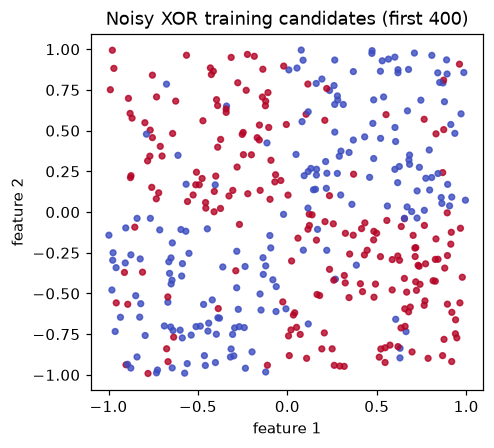

In [6]:
rows = []
for name in experiments.DATASETS:
    data = make_dataset(name)
    split = prepare_split(data, 96, experiments.DATA_SEEDS[0])
    rows.append([name, len(data.y_train_pool), len(data.y_val), len(data.y_test), data.x_val.shape[1],
                 f"{split.x_train.mean():+.1e}", f"{split.x_train.std():.3f}",
                 f"{split.x_val.mean():+.3f}"])
table(["Dataset", "Train reservoir", "Validation", "Test", "Features",
       "Mean of train features (n=96)", "SD of train features", "Mean of val features"], rows)

# The training subset is centered with unit spread by construction. The held-out pools are transformed with the
# training statistics and so are not exactly centered.
import matplotlib.pyplot as plt

xor = make_dataset("synthetic")
fig, ax = plt.subplots(figsize=(4.6, 4.2))
sample = slice(0, 400)
ax.scatter(xor.x_train_pool[sample, 0], xor.x_train_pool[sample, 1], c=xor.y_train_pool[sample],
           cmap="coolwarm", s=14, alpha=0.8)
ax.set_title("Noisy XOR training candidates (first 400)")
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
# topic9.figures selects the non-interactive Agg backend, so render to a buffer and display the image.
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
plt.close(fig)
display(Image(data=buffer.getvalue()))

### 2.3 Regularization and stopping rules

Unregularized and weight-decay fits stop when the training-objective gradient norm falls to 0.005 or after 800 updates,
and fits that reach the cap are labeled as such. For weight decay, each run chooses
$\lambda\in\{0.0005,0.005,0.05\}$ by minimum validation cross-entropy at the candidate's terminal iterate. Early stopping
checks validation loss at initialization and after every update. An improvement greater than $0.0002$ resets a patience
counter of 35 checks. When patience runs out, or at the shared 800-update cap, the earliest checkpoint with the lowest
observed validation loss is restored. The gradient-norm rule is switched off for early stopping so that validation loss
alone decides when to stop.

### 2.4 Random-label control

To measure memorization, the training, validation and test labels are replaced by independent draws from
$\operatorname{Bernoulli}(0.5)$, using a separate random stream for each split, while features, sample membership and
initial weights stay fixed. Each data seed fixes one draw per split for all paired model comparisons. A model cannot use
features to predict independent test labels, so expected test accuracy is 50%, and any gap between training and
held-out accuracy measures memorization of the training labels. A separate audit examines the correlations
between the drawn labels and the features and between the labels of different splits.

### 2.5 Compute budgets and diagnostic comparisons

At $n=96$, one checkpoint is a full training forward and gradient pass plus one validation forward pass. Its affine
multiply-accumulate count is $(2n+n_v)d$ for logistic regression and $(2n+n_v)\,m\,(d+1)$ for the network, where $n_v$ is
the validation size. The count leaves out biases, elementwise operations, logging, final scoring and data preparation, so
it is an architecture-sensitive compute proxy and not a measure of elapsed time.

Two budget rules are compared. Under the common-compute rule, every model receives the largest whole number of updates
whose checkpoints, counting the initial and the terminal one, fit under the cost of 181 checkpoints of width 8 on the same
dataset. Under the gradient rule, training stops when the gradient norm reaches 0.005 or after 800 updates.

Three controlled changes separate the possible causes of a poor fit, each holding data, seeds and learning rate fixed.
For optimization, a width-32 network on XOR with 256 examples is trained with update caps of 8, 800 and 3,000. For
representation, the linear model is replaced by the width-32 network on the same task. For overfitting, the unregularized
terminal iterate on WDBC with 32 examples is compared with the validation-selected checkpoint from the same starting
weights.

### 2.6 Runtime benchmark and convergence study

The runtime benchmark repeats the 16 conditions of the compute comparison, namely both datasets, logistic regression and
widths 2, 8 and 32, under both budget rules. Each matched run is timed after one untimed pass, with conditions
interleaved within each repeat, garbage collection paused and one BLAS thread. The timed region is the whole training
call, including the validation score at every checkpoint but excluding data preparation. To keep this stage short, the
notebook times five matched runs per condition (one per data seed) with three repeats each, whereas the report uses 15
matched runs and five repeats. The convergence study
uses the unregularized network on noisy XOR with 256 training examples at widths 8 and 32. The update cap is varied from
100 to 3,200 at learning rate 0.2, and separately the learning rate is varied from 0.05 to 1.6 at a cap of 800, with the
same gradient threshold of 0.005 and the same seeds.

## 3. Results

One call runs all 91 conditions of the main experiments: the capacity sweep, the three regularization methods, the
random-label controls, both budget rules and the diagnostics. Results are written to `topic9_nb/results/`.

In [7]:
print(quiet(experiments.run, RESULTS, quick=QUICK))
runs = load("runs.csv")

Wrote 1365 runs, 20882 curve points and 180 tuning rows.


### 3.1 Capacity and training-set size

Each cell gives mean test accuracy / cross-entropy over the 15 paired runs for hidden width 0 (logistic regression), 2,
8 and 32 and training sizes 32, 96 and 256.

| Dataset | n | Logistic | Width 2 | Width 8 | Width 32 |
|---|---|---|---|---|---|
| synthetic | 32 | 45.6% / 0.747 | 66.7% / 0.631 | 76.3% / 0.591 | 75.8% / 0.583 |
| synthetic | 96 | 47.3% / 0.706 | 72.2% / 0.554 | 81.7% / 0.462 | 82.6% / 0.460 |
| synthetic | 256 | 50.9% / 0.700 | 73.6% / 0.534 | 83.5% / 0.442 | 84.5% / 0.440 |
| wdbc | 32 | 94.6% / 0.218 | 93.7% / 0.226 | 94.0% / 0.219 | 94.0% / 0.225 |
| wdbc | 96 | 95.4% / 0.118 | 94.8% / 0.145 | 94.3% / 0.148 | 94.6% / 0.142 |
| wdbc | 256 | 97.1% / 0.084 | 94.4% / 0.128 | 95.8% / 0.109 | 96.0% / 0.084 |

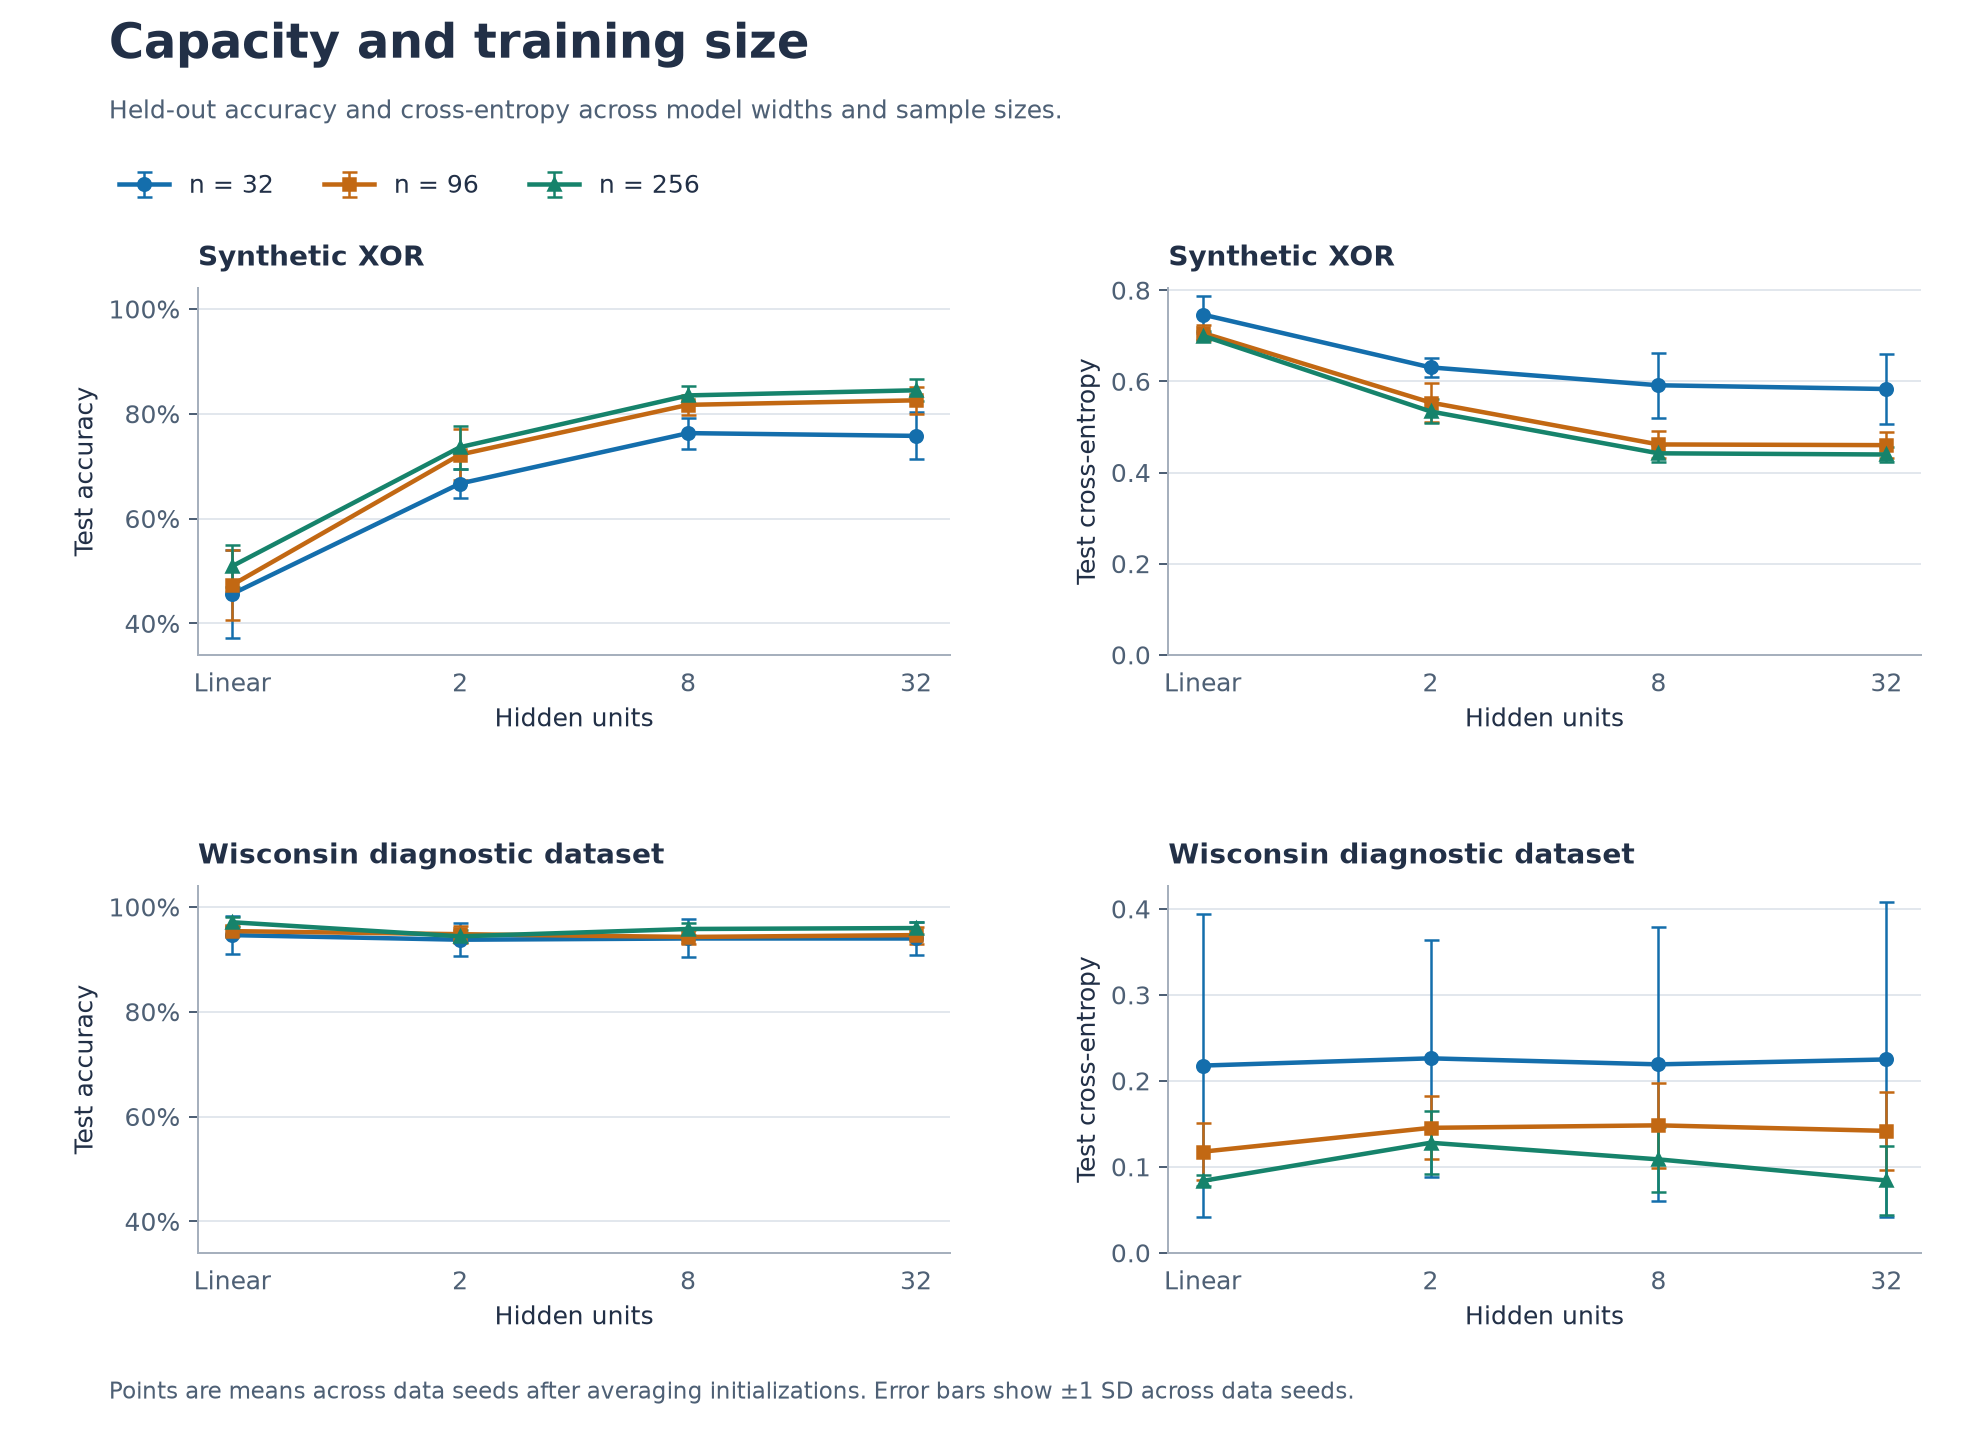

In [8]:
cap = select(runs, experiment="capacity")
body = []
for dataset in experiments.DATASETS:
    for size in experiments.TRAIN_SIZES:
        cells_ = []
        for width in experiments.WIDTHS:
            group = select(cap, dataset=dataset, train_size=size, width=width)
            cells_.append(f"{100*mean(group,'test_accuracy'):.1f}% / {mean(group,'test_loss'):.3f}")
        body.append([dataset, size, *cells_])
table(["Dataset", "n", "Logistic", "Width 2", "Width 8", "Width 32"], body)
show_figures("capacity")

Each network run is paired with the logistic run that has the same data seed and initialization seed. The differences
are averaged within each data seed first, so the spread below is the sample SD across the five data seeds. The 15 runs
share data seeds and are not independent.

In [9]:
pairs = list(capacity.summarize(RESULTS))
sd = lambda v: f"{float(v):.2f}" if v != "" else "n/a"
table(["Dataset", "n", "Width", "Accuracy change vs logistic (pp)", "Loss change vs logistic",
       "Data seeds with higher accuracy", "Data seeds with lower loss"],
      [[p["dataset"], p["train_size"], p["width"],
        f"{float(p['test_accuracy_delta_pp_mean']):+.1f} ± {sd(p['test_accuracy_delta_pp_sd'])}",
        f"{float(p['test_loss_delta_mean']):+.3f} ± {float(p['test_loss_delta_sd'] or 0):.3f}",
        f"{p['data_seeds_with_higher_accuracy']} / {p['n_data_seeds']}",
        f"{p['data_seeds_with_lower_loss']} / {p['n_data_seeds']}"] for p in pairs])

| Dataset | n | Width | Accuracy change vs logistic (pp) | Loss change vs logistic | Data seeds with higher accuracy | Data seeds with lower loss |
|---|---|---|---|---|---|---|
| synthetic | 32 | 2 | +21.1 ± 8.64 | -0.116 ± 0.026 | 5 / 5 | 5 / 5 |
| synthetic | 32 | 8 | +30.7 ± 10.96 | -0.155 ± 0.079 | 5 / 5 | 5 / 5 |
| synthetic | 32 | 32 | +30.2 ± 12.45 | -0.163 ± 0.089 | 5 / 5 | 5 / 5 |
| synthetic | 96 | 2 | +24.9 ± 6.94 | -0.153 ± 0.025 | 5 / 5 | 5 / 5 |
| synthetic | 96 | 8 | +34.4 ± 6.10 | -0.245 ± 0.014 | 5 / 5 | 5 / 5 |
| synthetic | 96 | 32 | +35.2 ± 6.07 | -0.246 ± 0.015 | 5 / 5 | 5 / 5 |
| synthetic | 256 | 2 | +22.7 ± 6.02 | -0.166 ± 0.019 | 5 / 5 | 5 / 5 |
| synthetic | 256 | 8 | +32.6 ± 4.41 | -0.258 ± 0.014 | 5 / 5 | 5 / 5 |
| synthetic | 256 | 32 | +33.6 ± 4.25 | -0.261 ± 0.011 | 5 / 5 | 5 / 5 |
| wdbc | 32 | 2 | -0.9 ± 1.03 | +0.008 ± 0.040 | 0 / 5 | 2 / 5 |
| wdbc | 32 | 8 | -0.6 ± 1.21 | +0.001 ± 0.033 | 1 / 5 | 3 / 5 |
| wdbc | 32 | 32 | -0.6 ± 0.96 | +0.007 ± 0.015 | 2 / 5 | 2 / 5 |
| wdbc | 96 | 2 | -0.6 ± 2.04 | +0.028 ± 0.030 | 2 / 5 | 1 / 5 |
| wdbc | 96 | 8 | -1.1 ± 1.51 | +0.031 ± 0.036 | 1 / 5 | 1 / 5 |
| wdbc | 96 | 32 | -0.8 ± 1.27 | +0.024 ± 0.027 | 1 / 5 | 1 / 5 |
| wdbc | 256 | 2 | -2.7 ± 1.52 | +0.044 ± 0.033 | 0 / 5 | 0 / 5 |
| wdbc | 256 | 8 | -1.3 ± 1.27 | +0.025 ± 0.035 | 1 / 5 | 1 / 5 |
| wdbc | 256 | 32 | -1.1 ± 1.06 | +0.000 ± 0.037 | 1 / 5 | 4 / 5 |

On noisy XOR with 256 training examples, test accuracy rose from 73.6% at width 2 to 83.5% at width 8, then to 84.5% at
width 32. The biggest gain came from going from 2 to 8 hidden units. More data also helped at a fixed width. The 32-unit
network went from 75.8% accuracy with 32 examples to 84.5% with 256.

To check how consistent the improvement was, we compared each network run with logistic regression trained on the same
examples. We averaged the paired differences over three initializations for each of the five data seeds. On noisy XOR
with 256 examples, width 32 beat logistic regression by an average of 33.6 percentage points, with a standard deviation of
4.3 points across the five seeds. It improved both accuracy and cross-entropy on all five seed averages.

On WDBC, logistic regression had higher mean test accuracy than every network at each training size in the unregularized
sweep. With 256 examples, it scored 97.1% compared with 96.0% for width 32, and both had a cross-entropy of about 0.084.
The nonlinear hidden layer helped on XOR, where a straight line cannot separate the classes. On WDBC, the linear baseline
already performed well.

### 3.2 Regularization

The tables compare an unregularized fit, weight decay and early stopping for the width-32 network. The last table shows
where early stopping restored its checkpoint (update 0 is the initial model) and how test accuracy changed against the
matched unregularized fit.

| Dataset | n | No regularization | Weight decay | Early stopping |
|---|---|---|---|---|
| synthetic | 32 | 0.583 (75.8%) | 0.534 (75.6%) | 0.613 (62.5%) |
| synthetic | 256 | 0.440 (84.5%) | 0.440 (84.5%) | 0.529 (73.3%) |
| wdbc | 32 | 0.225 (94.0%) | 0.153 (94.7%) | 0.139 (95.0%) |
| wdbc | 256 | 0.084 (96.0%) | 0.078 (96.5%) | 0.070 (97.1%) |

| Dataset | n | Selected weight decay (all runs) |
|---|---|---|
| synthetic | 32 | 0.005 |
| synthetic | 256 | 0.0005, 0.005 |
| wdbc | 32 | 0.0005, 0.005, 0.05 |
| wdbc | 256 | 0.0005, 0.005 |

| XOR, n | Group | Runs | Mean restored update | Mean test-accuracy change |
|---|---|---|---|---|
| 32 | restored update <= 9 | 8 | 3 | -26.0 pp |
| 32 | restored update > 9 | 7 | 304 | +1.2 pp |
| 256 | restored update <= 9 | 5 | 6 | -34.0 pp |
| 256 | restored update > 9 | 10 | 672 | +0.3 pp |

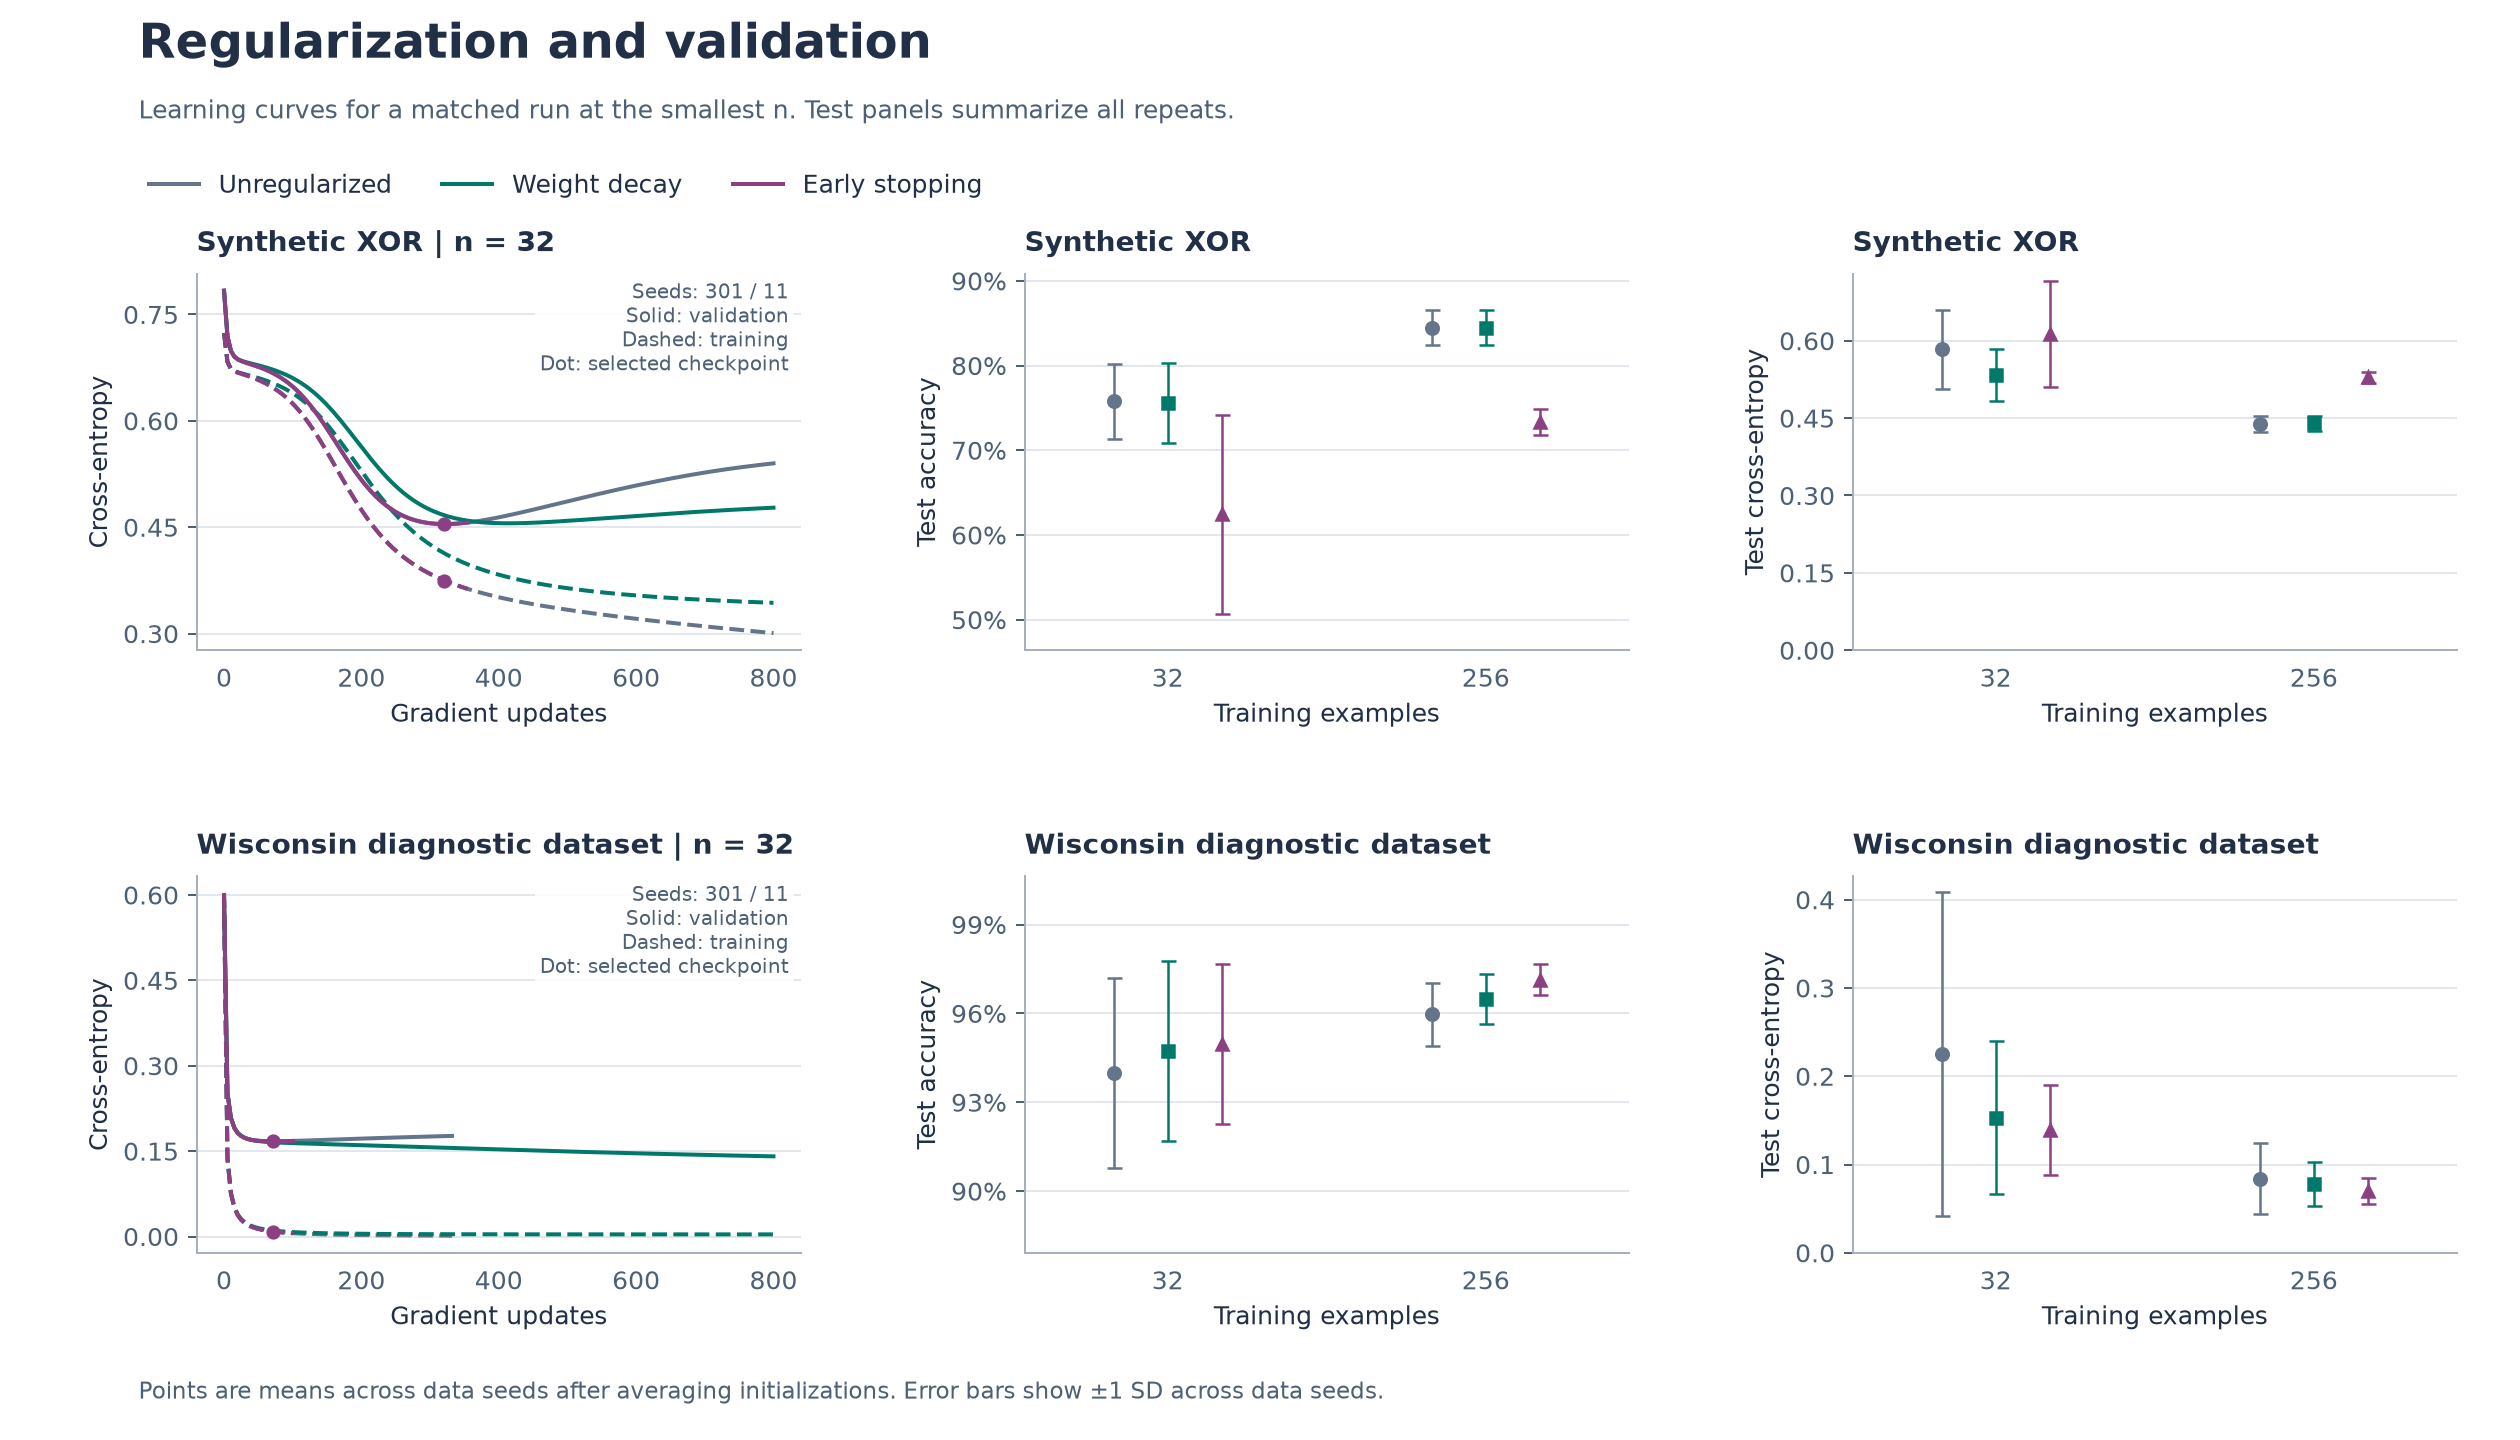

In [10]:
reg = select(runs, experiment="regularization")
body = []
for dataset in experiments.DATASETS:
    for size in (32, 256):
        row = [dataset, size]
        for method in ("none", "weight_decay", "early_stopping"):
            group = select(reg, dataset=dataset, train_size=size, regularization=method)
            row.append(f"{mean(group,'test_loss'):.3f} ({100*mean(group,'test_accuracy'):.1f}%)")
        body.append(row)
table(["Dataset", "n", "No regularization", "Weight decay", "Early stopping"], body)

tuning = load("tuning.csv")
chosen = {}
for r in select(tuning, selected=1):
    chosen.setdefault((r["dataset"], r["train_size"]), []).append(r["decay"])
table(["Dataset", "n", "Selected weight decay (all runs)"],
      [[d, n, ", ".join(f"{v:g}" for v in sorted(set(vals)))] for (d, n), vals in sorted(chosen.items())])

base = {(r["dataset"], r["train_size"], r["data_seed"], r["init_seed"]): r
        for r in reg if r["regularization"] == "none"}
body = []
for size in (32, 256):
    es = select(reg, dataset="synthetic", train_size=size, regularization="early_stopping")
    change = lambda r: 100 * (r["test_accuracy"] - base[(r["dataset"], r["train_size"], r["data_seed"], r["init_seed"])]["test_accuracy"])
    for label, group in (("restored update <= 9", [r for r in es if r["selected_step"] <= 9]),
                         ("restored update > 9", [r for r in es if r["selected_step"] > 9])):
        body.append([size, label, len(group),
                     f"{st.mean(r['selected_step'] for r in group):.0f}" if group else "-",
                     f"{st.mean(change(r) for r in group):+.1f} pp" if group else "-"])
table(["XOR, n", "Group", "Runs", "Mean restored update", "Mean test-accuracy change"], body)
show_figures("regularization")

### 3.3 Random-label control

The first table compares clean and random labels. Because the test labels are independent of the model, the number of
correct test predictions is exactly $\operatorname{Binomial}(n_\text{test},0.5)$, and the second table counts how many
random-label runs fall inside the central 95% interval and how many fit every training label. The label audit checks that
the largest absolute feature-label correlation of each draw stays below a Bonferroni-style threshold. One width-2 WDBC
random-label fit ($n=96$) stops almost exactly at the gradient threshold, so a rerun on another machine can count 230 runs
inside the interval where the archived results have 229. Models share label draws across conditions, and the two datasets
reuse the same label seeds, so this count is descriptive and not a formal test.

| Dataset | n | Model | Clean labels: train / test | Random labels: train / test |
|---|---|---|---|---|
| synthetic | 32 | Logistic | 52.3% / 45.6% | 62.7% / 49.9% |
| synthetic | 32 | Width 32 | 88.3% / 75.8% | 74.8% / 49.6% |
| synthetic | 96 | Logistic | 54.1% / 47.3% | 56.5% / 50.1% |
| synthetic | 96 | Width 32 | 85.3% / 82.6% | 64.4% / 50.2% |
| wdbc | 32 | Logistic | 100.0% / 94.6% | 92.3% / 48.5% |
| wdbc | 32 | Width 32 | 100.0% / 94.0% | 100.0% / 49.8% |
| wdbc | 96 | Logistic | 99.6% / 95.4% | 72.6% / 49.1% |
| wdbc | 96 | Width 32 | 100.0% / 94.6% | 100.0% / 49.2% |

| Dataset | n | Model | Train acc. | Test acc. | Runs fitting all train labels | 95% chance interval | Runs inside interval |
|---|---|---|---|---|---|---|---|
| synthetic | 32 | Logistic | 62.71% | 49.92% | 0 / 15 | [47.9, 52.1] | 15 / 15 |
| synthetic | 32 | Width 2 | 70.62% | 49.64% | 0 / 15 | [47.9, 52.1] | 12 / 15 |
| synthetic | 32 | Width 8 | 76.46% | 49.50% | 0 / 15 | [47.9, 52.1] | 12 / 15 |
| synthetic | 32 | Width 32 | 74.79% | 49.61% | 0 / 15 | [47.9, 52.1] | 15 / 15 |
| synthetic | 96 | Logistic | 56.46% | 50.09% | 0 / 15 | [47.9, 52.1] | 15 / 15 |
| synthetic | 96 | Width 2 | 60.76% | 50.02% | 0 / 15 | [47.9, 52.1] | 15 / 15 |
| synthetic | 96 | Width 8 | 64.79% | 50.07% | 0 / 15 | [47.9, 52.1] | 15 / 15 |
| synthetic | 96 | Width 32 | 64.44% | 50.16% | 0 / 15 | [47.9, 52.1] | 15 / 15 |
| wdbc | 32 | Logistic | 92.29% | 48.54% | 3 / 15 | [41.2, 58.8] | 13 / 15 |
| wdbc | 32 | Width 2 | 95.62% | 47.43% | 2 / 15 | [41.2, 58.8] | 14 / 15 |
| wdbc | 32 | Width 8 | 100.00% | 49.77% | 15 / 15 | [41.2, 58.8] | 15 / 15 |
| wdbc | 32 | Width 32 | 100.00% | 49.77% | 15 / 15 | [41.2, 58.8] | 15 / 15 |
| wdbc | 96 | Logistic | 72.64% | 49.12% | 0 / 15 | [41.2, 58.8] | 15 / 15 |
| wdbc | 96 | Width 2 | 75.76% | 50.12% | 0 / 15 | [41.2, 58.8] | 15 / 15 |
| wdbc | 96 | Width 8 | 99.38% | 49.42% | 9 / 15 | [41.2, 58.8] | 14 / 15 |
| wdbc | 96 | Width 32 | 100.00% | 49.24% | 15 / 15 | [41.2, 58.8] | 15 / 15 |

Inside the chance interval: 230 of 240 random-label runs
Label audit: 30 of 30 draws have every feature correlation below the threshold; closest is 0.2075 against 0.2288 (synthetic, train, seed 303)


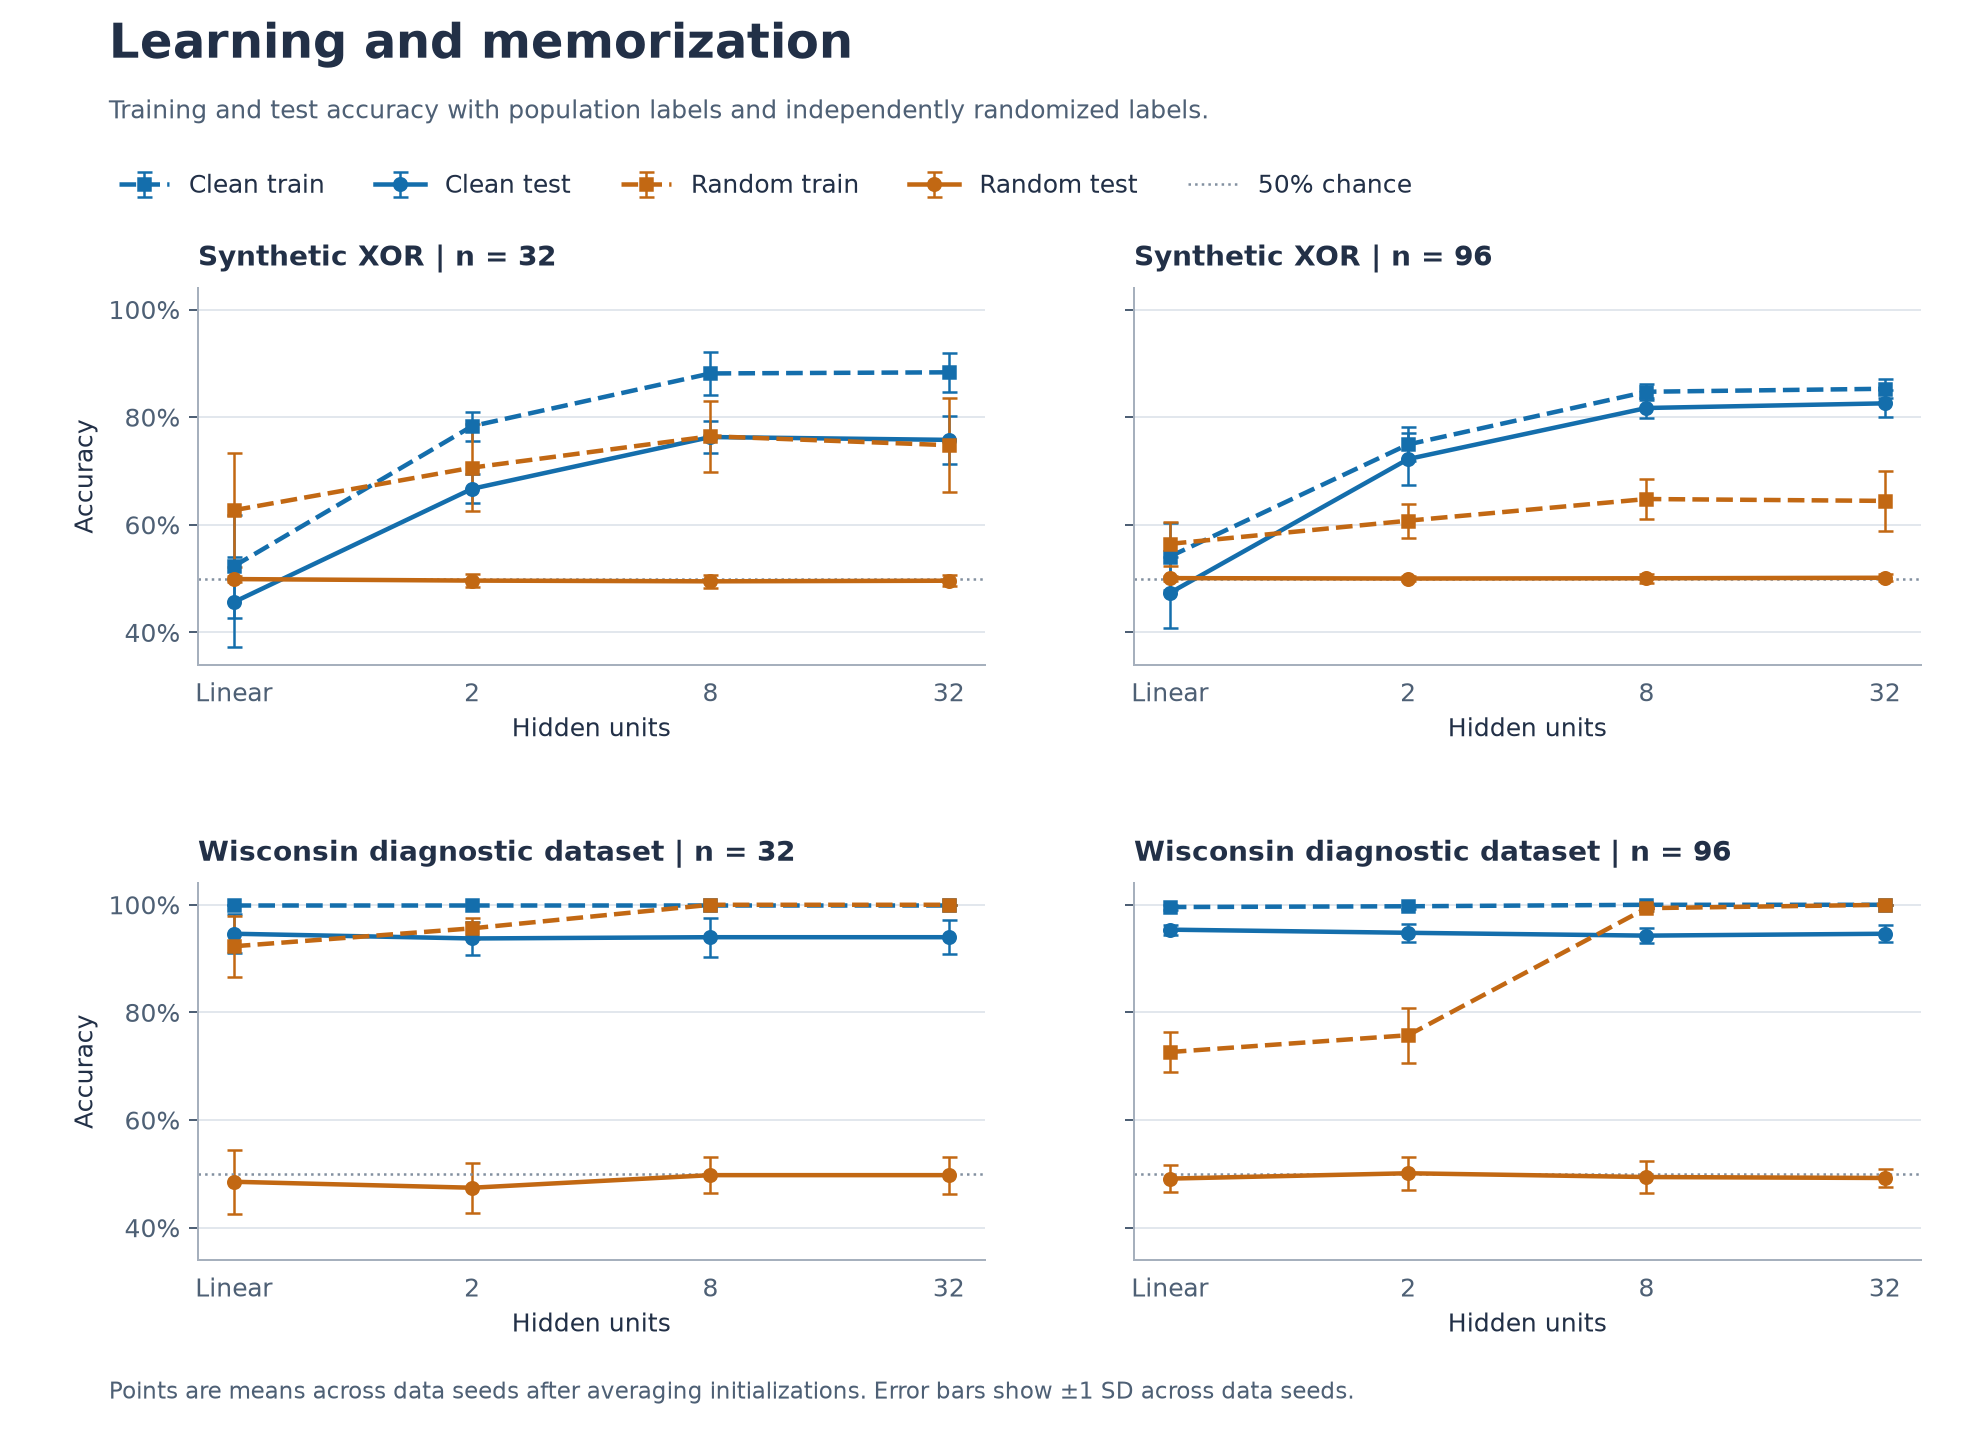

In [11]:
rl = select(runs, experiment="random_labels")
body = []
for dataset in experiments.DATASETS:
    for size in (32, 96):
        for width in (0, 32):
            clean = select(rl, dataset=dataset, train_size=size, width=width, labels="clean")
            rand = select(rl, dataset=dataset, train_size=size, width=width, labels="random")
            body.append([dataset, size, "Logistic" if width == 0 else f"Width {width}",
                         f"{100*mean(clean,'train_accuracy'):.1f}% / {100*mean(clean,'test_accuracy'):.1f}%",
                         f"{100*mean(rand,'train_accuracy'):.1f}% / {100*mean(rand,'test_accuracy'):.1f}%"])
table(["Dataset", "n", "Model", "Clean labels: train / test", "Random labels: train / test"], body)

chance = [r for r in random_labels.summarize(RESULTS) if r["labels"] == "random"]
table(["Dataset", "n", "Model", "Train acc.", "Test acc.", "Runs fitting all train labels",
       "95% chance interval", "Runs inside interval"],
      [[r["dataset"], r["train_size"], "Logistic" if r["width"] == 0 else f"Width {r['width']}",
        f"{r['train_accuracy_mean']}%", f"{r['test_accuracy_mean']}%",
        f"{r['runs_fitting_all_train_labels']} / {r['n_runs']}", r["chance_interval"],
        f"{r['runs_inside_chance_interval']} / {r['n_runs']}"] for r in chance])
inside = sum(r["runs_inside_chance_interval"] for r in chance)
print(f"Inside the chance interval: {inside} of {sum(r['n_runs'] for r in chance)} random-label runs")

audit = list(random_labels.audit(experiments.DATA_SEEDS[:1] if QUICK else experiments.DATA_SEEDS, 96))
ratio = lambda a: float(a["max_abs_feature_correlation"]) / float(a["correlation_bound"])
closest = max(audit, key=ratio)
print(f"Label audit: {sum(ratio(a) < 1 for a in audit)} of {len(audit)} draws have every feature correlation below the "
      f"threshold; closest is {closest['max_abs_feature_correlation']} against {closest['correlation_bound']} "
      f"({closest['dataset']}, {closest['split']}, seed {closest['data_seed']})")
show_figures("random_labels")

### 3.4 Compute budgets and diagnoses

The first table compares the two budget rules at $n=96$ and records how many runs met the gradient threshold. The second
table gives the three controlled changes.

| Dataset | Model | Common compute | Gradient rule with cap | Converged runs |
|---|---|---|---|---|
| synthetic | Logistic | 2171 updates, 47.3% / 0.707 | 83 updates, 47.3% / 0.706 | 15 / 15 |
| synthetic | Width 2 | 723 updates, 72.2% / 0.553 | 788 updates, 72.2% / 0.554 | 2 / 15 |
| synthetic | Width 8 | 180 updates, 74.6% / 0.554 | 800 updates, 81.7% / 0.462 | 0 / 15 |
| synthetic | Width 32 | 44 updates, 49.4% / 0.699 | 800 updates, 82.6% / 0.460 | 0 / 15 |
| wdbc | Logistic | 1495 updates, 94.7% / 0.134 | 800 updates, 95.4% / 0.118 | 0 / 15 |
| wdbc | Width 2 | 723 updates, 94.9% / 0.142 | 797 updates, 94.8% / 0.145 | 2 / 15 |
| wdbc | Width 8 | 180 updates, 95.4% / 0.117 | 743 updates, 94.3% / 0.148 | 9 / 15 |
| wdbc | Width 32 | 44 updates, 96.4% / 0.102 | 710 updates, 94.6% / 0.142 | 9 / 15 |

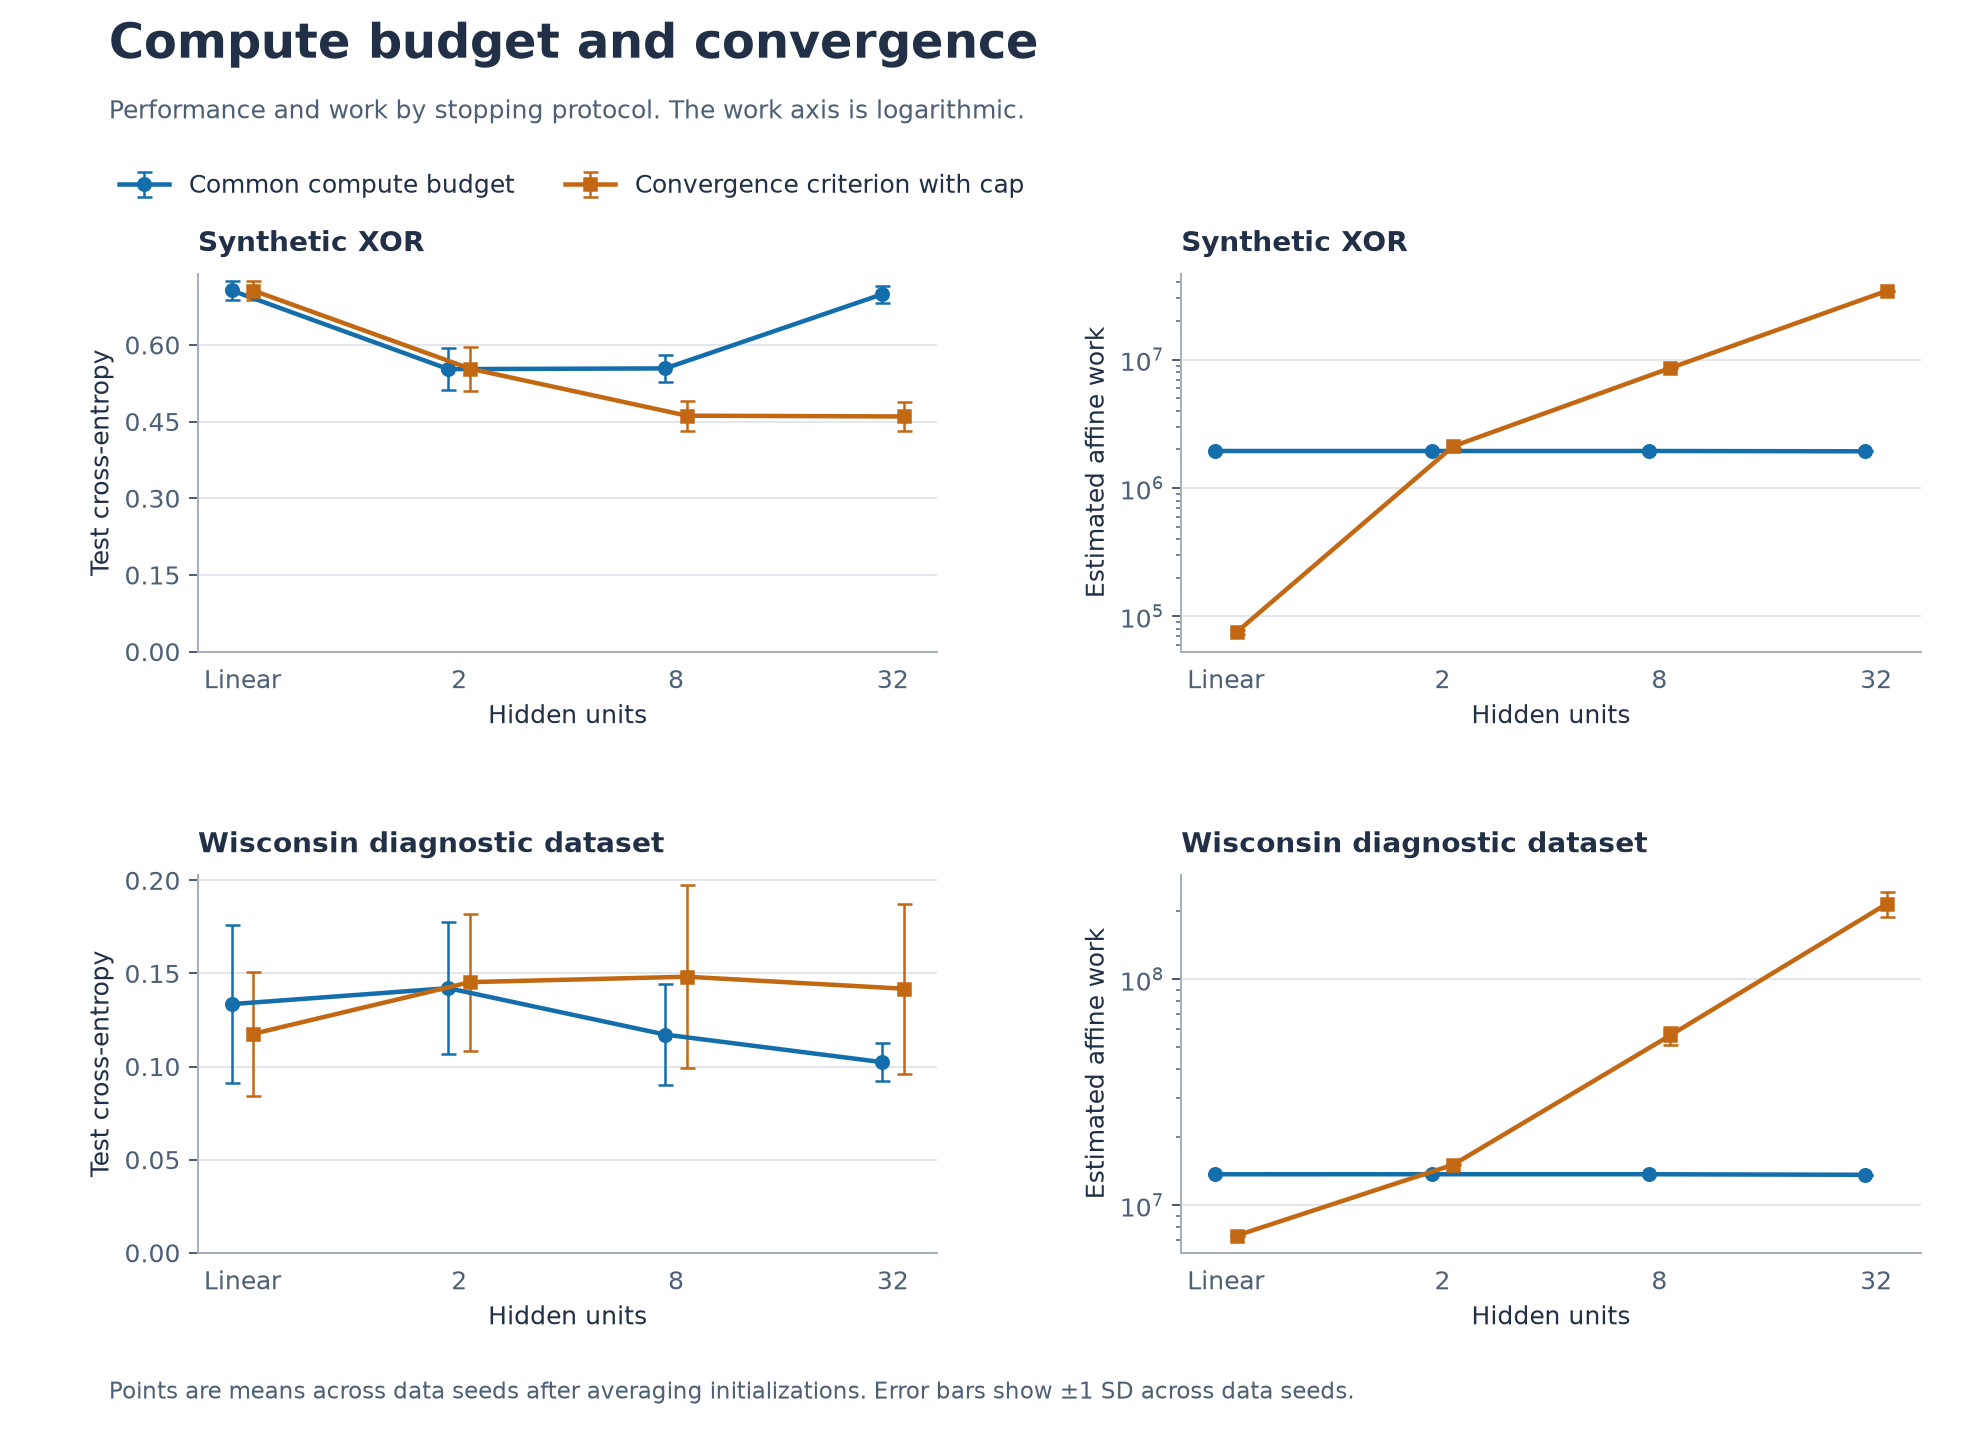

| Change | Train loss | Validation loss | Test loss | Converged after change |
|---|---|---|---|---|
| Optimization: 8 -> 800 updates | 0.689 -> 0.379 | 0.701 -> 0.422 | 0.702 -> 0.440 | 0 / 15 |
| Optimization: 800 -> 3,000 updates | 0.379 -> 0.323 | 0.422 -> 0.429 | 0.440 -> 0.443 | 1 / 15 |
| Representation: linear -> width 32 | 0.687 -> 0.379 | 0.701 -> 0.422 | 0.700 -> 0.440 | 0 / 15 |
| Overfitting: terminal -> validation-selected | 0.002 -> 0.035 | 0.250 -> 0.166 | 0.225 -> 0.139 | 0 / 15 |

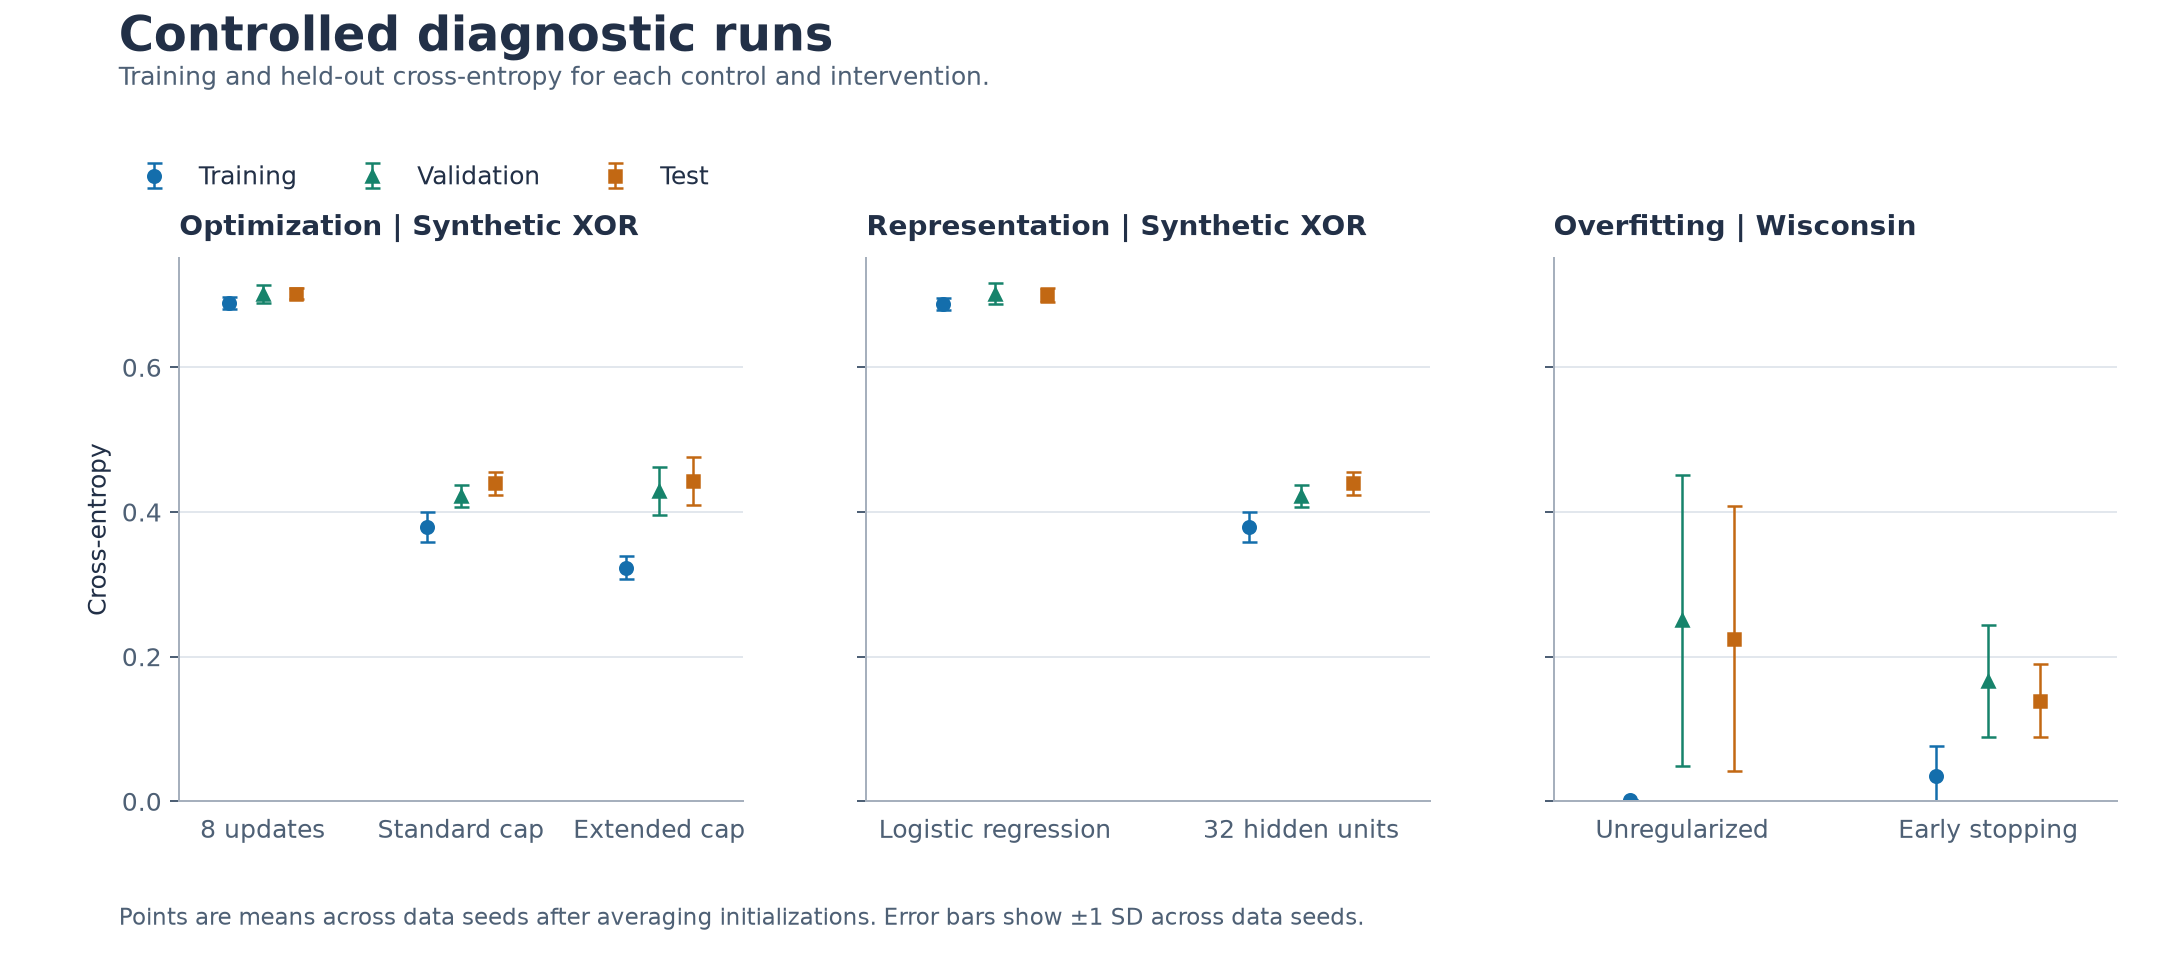

In [12]:
bud = select(runs, experiment="budget")
body = []
for dataset in experiments.DATASETS:
    for width in experiments.WIDTHS:
        row = [dataset, "Logistic" if width == 0 else f"Width {width}"]
        for rule in ("fixed", "convergence"):
            g = select(bud, dataset=dataset, width=width, budget=rule)
            row.append(f"{mean(g,'steps'):.0f} updates, {100*mean(g,'test_accuracy'):.1f}% / {mean(g,'test_loss'):.3f}")
            if rule == "convergence":
                row.append(f"{sum(r['stop_reason'] == 'converged' for r in g)} / {len(g)}")
        body.append(row)
table(["Dataset", "Model", "Common compute", "Gradient rule with cap", "Converged runs"], body)
show_figures("budget")

diag = select(runs, experiment="diagnostic")
pairs = [("Optimization: 8 -> 800 updates", "optimization_short", "optimization_long"),
         ("Optimization: 800 -> 3,000 updates", "optimization_long", "optimization_extended"),
         ("Representation: linear -> width 32", "representation_linear", "representation_wide"),
         ("Overfitting: terminal -> validation-selected", "overfit_unregularized", "overfit_early_stopping")]
body = []
for label, before, after in pairs:
    a, b = select(diag, condition=before), select(diag, condition=after)
    body.append([label] + [f"{mean(a,m):.3f} -> {mean(b,m):.3f}" for m in ("train_loss", "val_loss", "test_loss")]
                + [f"{sum(r['stop_reason']=='converged' for r in b)} / {len(b)}"])
table(["Change", "Train loss", "Validation loss", "Test loss", "Converged after change"], body)
show_figures("diagnostic")

### 3.5 Runtime against estimated work

The table gives the median training time per matched run (five matched runs, three repeats each) and the time per
checkpoint under both budget rules. The fits that follow compare how well estimated work, the number of checkpoints, or
both predict measured time. The errors in the cost-model table are fit errors on the same 16 conditions used to fit the
models, not out-of-sample predictions. Absolute times depend on the machine, so only the comparisons between conditions
carry over.

Wrote 240 timings for 16 conditions.


| Dataset | Model | Common compute: updates, seconds | Gradient rule: updates, seconds | µs per checkpoint (common / gradient) |
|---|---|---|---|---|
| synthetic | Logistic | 2171, 0.1070 | 83, 0.0043 | 49 / 51 |
| synthetic | Width 2 | 723, 0.0613 | 800, 0.0695 | 85 / 87 |
| synthetic | Width 8 | 180, 0.0214 | 800, 0.0916 | 118 / 114 |
| synthetic | Width 32 | 44, 0.0103 | 800, 0.1750 | 228 / 218 |
| wdbc | Logistic | 1495, 0.0713 | 800, 0.0381 | 48 / 48 |
| wdbc | Width 2 | 723, 0.0604 | 793, 0.0678 | 84 / 86 |
| wdbc | Width 8 | 180, 0.0192 | 756, 0.0809 | 106 / 107 |
| wdbc | Width 32 | 44, 0.0085 | 711, 0.1235 | 190 / 174 |

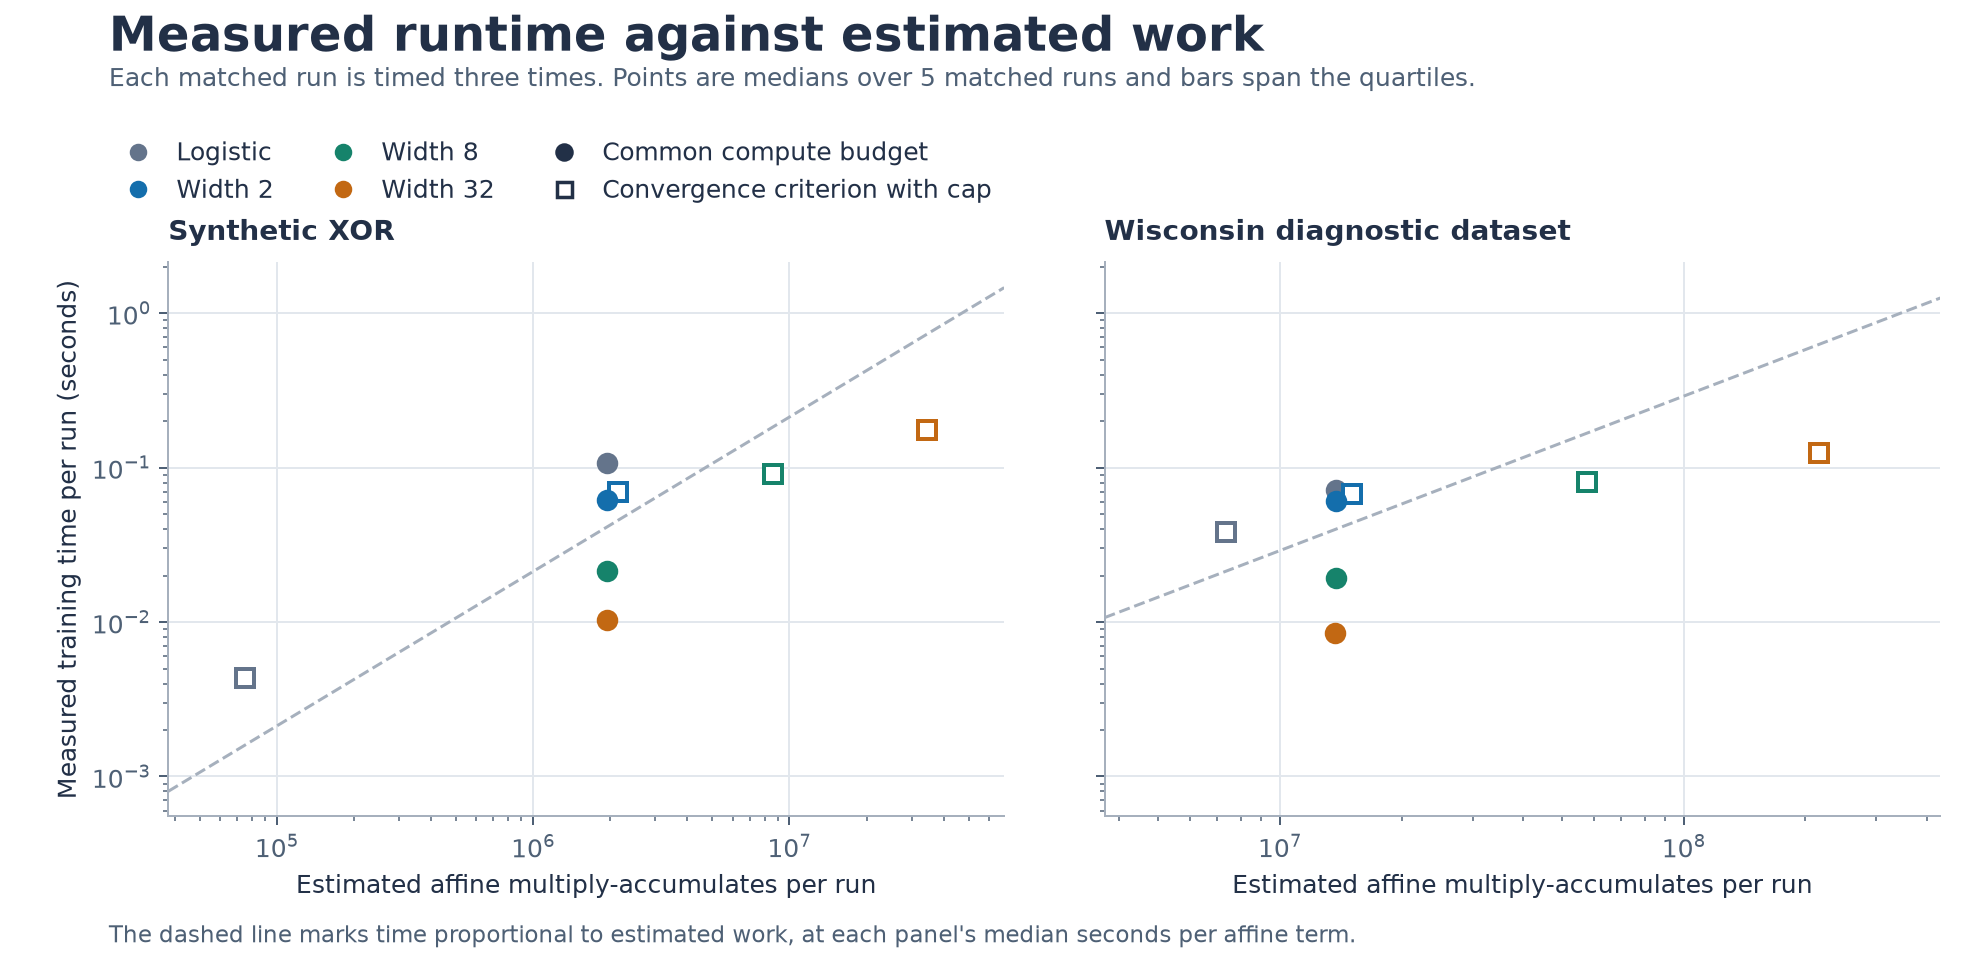

Log-log fit of time on work across the 16 conditions: slope 0.35, R^2 0.37


| Runtime model | Median relative error | Max relative error |
|---|---|---|
| work only | 82% | 98% |
| updates only | 40% | 69% |
| updates plus work | 26% | 64% |

synthetic: at equal estimated work, time ranges 0.0103 to 0.1070 s (factor 10.4)
wdbc: at equal estimated work, time ranges 0.0085 to 0.0713 s (factor 8.3)


In [13]:
print(quiet(benchmark.run, RESULTS, quick=QUICK, init_seeds=experiments.INIT_SEEDS[:1],
            repeats=None if QUICK else 3))
rt = load("runtime_summary.csv")
by_key = {(r["dataset"], r["width"], r["budget"]): r for r in rt}
body = []
for dataset in experiments.DATASETS:
    for width in experiments.WIDTHS:
        a, b = by_key[(dataset, width, "fixed")], by_key[(dataset, width, "convergence")]
        body.append([dataset, "Logistic" if width == 0 else f"Width {width}",
                     f"{a['mean_updates']:.0f}, {a['median_seconds']:.4f}", f"{b['mean_updates']:.0f}, {b['median_seconds']:.4f}",
                     f"{a['microseconds_per_checkpoint']:.0f} / {b['microseconds_per_checkpoint']:.0f}"])
table(["Dataset", "Model", "Common compute: updates, seconds", "Gradient rule: updates, seconds",
       "µs per checkpoint (common / gradient)"], body)
show_figures("runtime")

meta = json.load(open(RESULTS / "runtime.json", encoding="utf-8"))
fits, models = meta["fits"], meta["cost_models"]
print(f"Log-log fit of time on work across the 16 conditions: slope {fits['pooled']['slope']:.2f}, "
      f"R^2 {fits['pooled']['r_squared']:.2f}")
table(["Runtime model", "Median relative error", "Max relative error"],
      [[name.replace("_", " "), f"{m['median_relative_error']:.0%}", f"{m['max_relative_error']:.0%}"]
       for name, m in models.items()])
fixed = [r for r in rt if r["budget"] == "fixed"]
for dataset in experiments.DATASETS:
    times = {r["width"]: r["median_seconds"] for r in fixed if r["dataset"] == dataset}
    print(f"{dataset}: at equal estimated work, time ranges {min(times.values()):.4f} to {max(times.values()):.4f} s "
          f"(factor {max(times.values())/min(times.values()):.1f})")

### 3.6 Convergence sensitivity on noisy XOR

The tables show the width-32 network. The cap sweep holds the learning rate at 0.2, and the learning-rate sweep holds the
cap at 800. Every run also records the validation loss, the number of updates at which training loss increased, and the
reason it stopped, and the figure covers widths 8 and 32.

Wrote 360 convergence runs.


#### Update cap (learning rate 0.2)

| Setting | Converged | Mean updates | Train loss | Test loss | Final grad. norm | Runs with loss increases |
|---|---|---|---|---|---|---|
| 100 | 0 / 15 | 100 | 0.659 | 0.674 | 0.0526 | 0 |
| 200 | 0 / 15 | 200 | 0.550 | 0.568 | 0.0831 | 0 |
| 400 | 0 / 15 | 400 | 0.417 | 0.446 | 0.0306 | 0 |
| 800 | 0 / 15 | 800 | 0.379 | 0.440 | 0.0168 | 0 |
| 1600 | 0 / 15 | 1600 | 0.348 | 0.441 | 0.0112 | 0 |
| 3200 | 1 / 15 | 3152 | 0.320 | 0.444 | 0.0082 | 0 |

#### Learning rate (cap 800)

| Setting | Converged | Mean updates | Train loss | Test loss | Final grad. norm | Runs with loss increases |
|---|---|---|---|---|---|---|
| 0.05 | 0 / 15 | 800 | 0.548 | 0.567 | 0.0831 | 0 |
| 0.1 | 0 / 15 | 800 | 0.417 | 0.446 | 0.0306 | 0 |
| 0.2 | 0 / 15 | 800 | 0.379 | 0.440 | 0.0168 | 0 |
| 0.4 | 0 / 15 | 800 | 0.348 | 0.441 | 0.0112 | 0 |
| 0.8 | 1 / 15 | 788 | 0.320 | 0.444 | 0.0082 | 0 |
| 1.6 | 4 / 15 | 734 | 0.291 | 0.460 | 0.0125 | 1 |

Width 8 at learning rate 1.6: 9 of 15 runs converge.


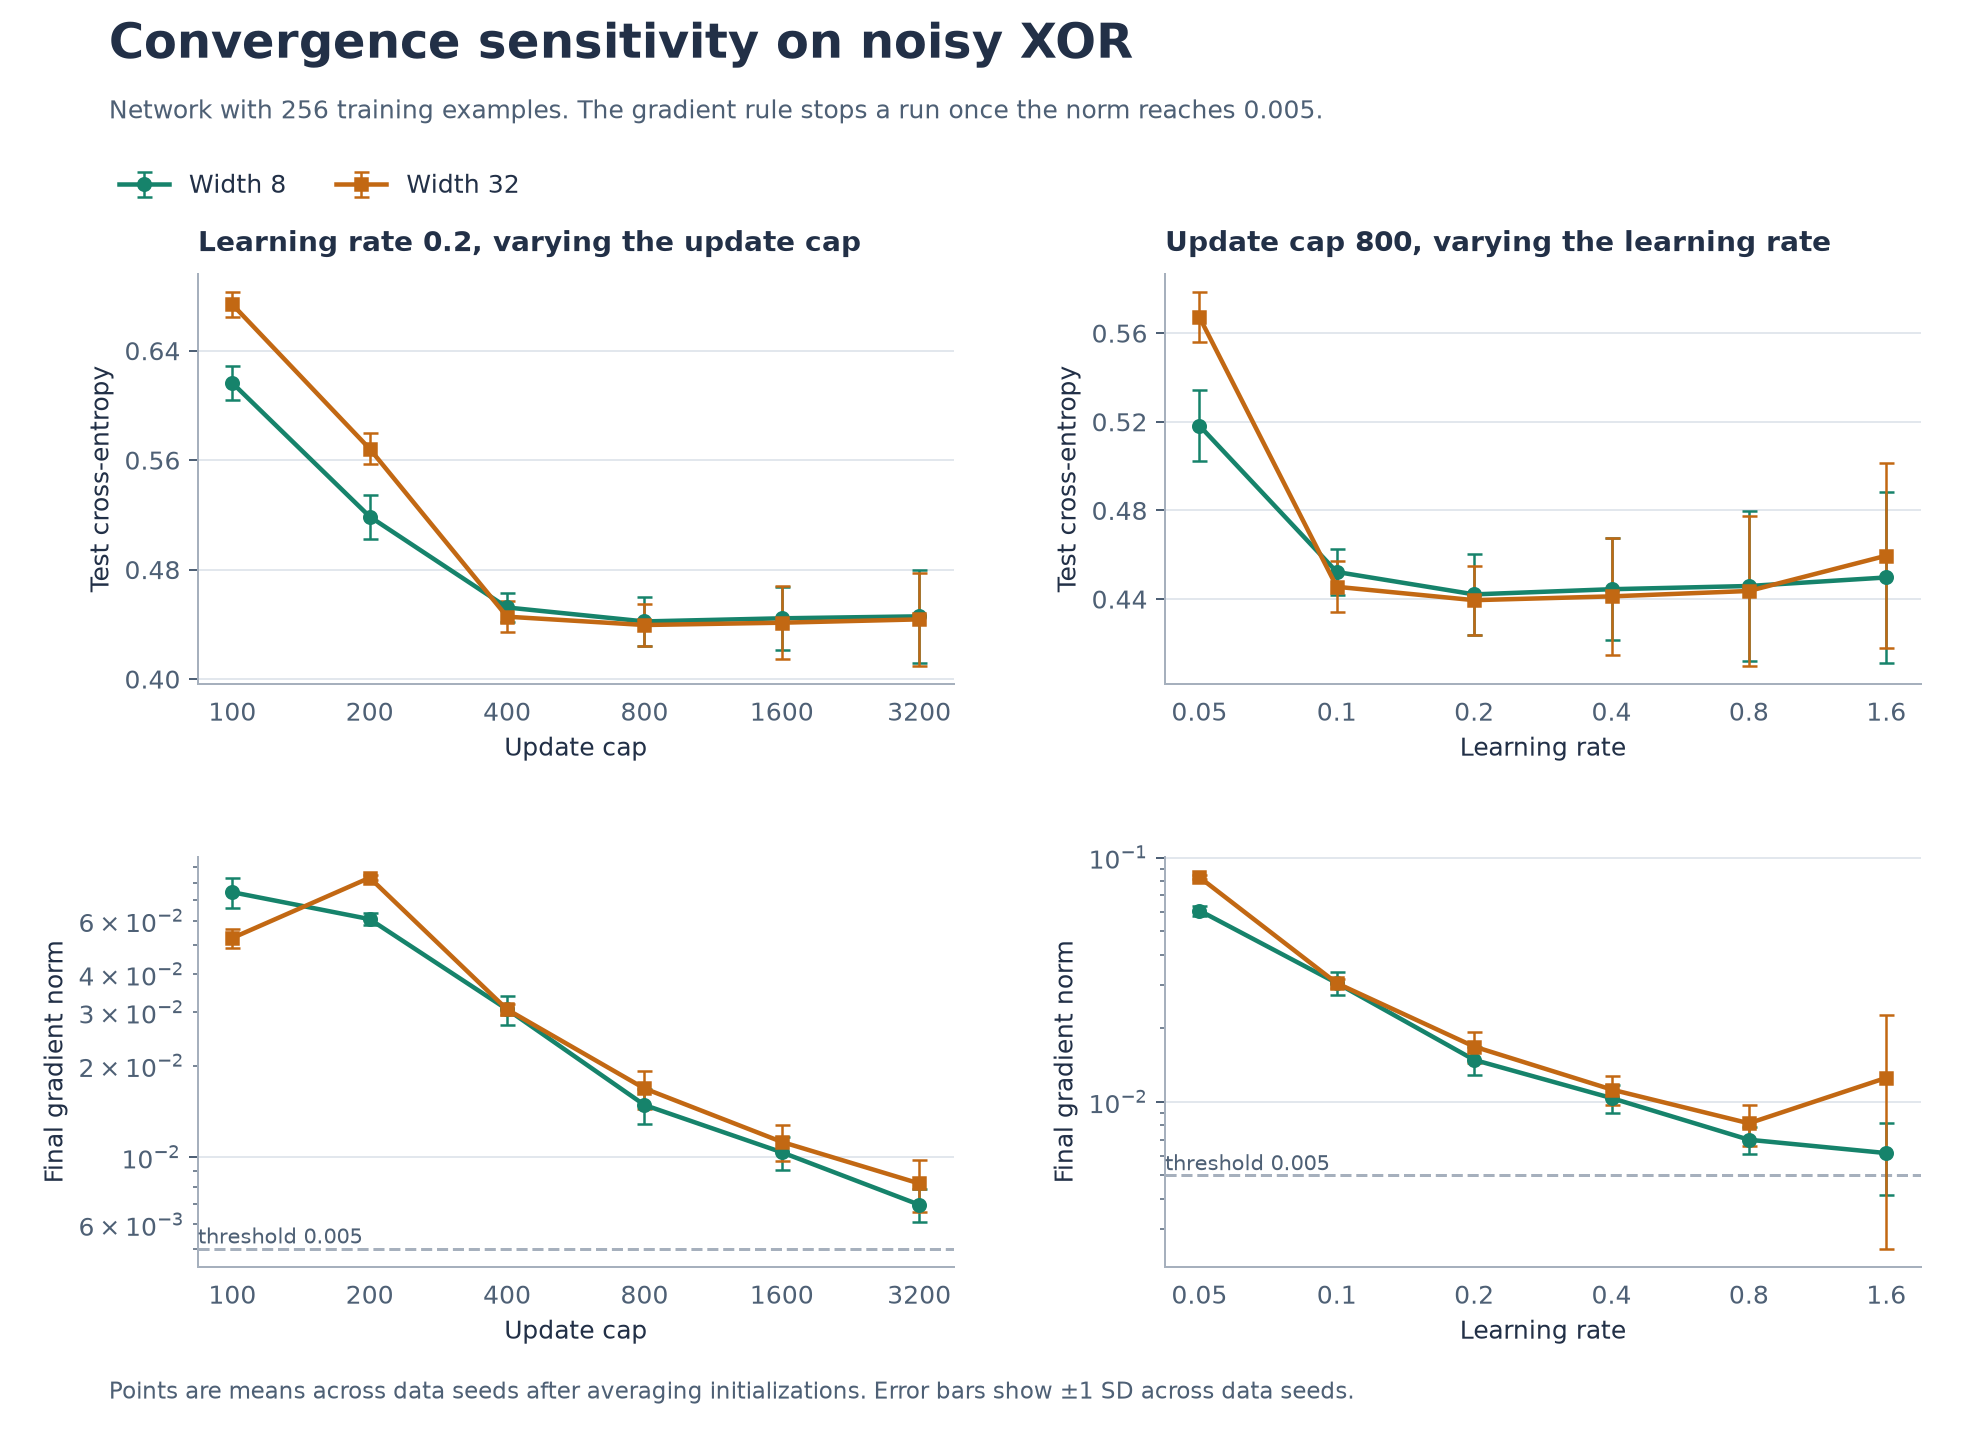

In [14]:
print(quiet(sensitivity.run, RESULTS, quick=QUICK))
conv = load("convergence.csv")


def row_for(sweep, width, field, level):
    g = [r for r in select(conv, sweep=sweep, width=width) if r[field] == level]
    ok = sum(r["stop_reason"] == "converged" for r in g)
    return [f"{level:g}", f"{ok} / {len(g)}", f"{mean(g,'steps'):.0f}", f"{mean(g,'train_loss'):.3f}",
            f"{mean(g,'test_loss'):.3f}", f"{mean(g,'final_gradient_norm'):.4f}",
            sum(1 for r in g if r["loss_increases"] > 0)]


heads = ["Setting", "Converged", "Mean updates", "Train loss", "Test loss", "Final grad. norm", "Runs with loss increases"]
width = 32
display(Markdown("#### Update cap (learning rate 0.2)"))
table(heads, [row_for("cap", width, "max_steps", c) for c in sensitivity.CAPS if select(conv, sweep="cap", width=width, max_steps=c)])
display(Markdown("#### Learning rate (cap 800)"))
table(heads, [row_for("learning_rate", width, "learning_rate", lr) for lr in sensitivity.LEARNING_RATES
              if select(conv, sweep="learning_rate", width=width, learning_rate=lr)])
w8 = select(conv, sweep="learning_rate", width=8, learning_rate=1.6)
print(f"Width 8 at learning rate 1.6: {sum(r['stop_reason'] == 'converged' for r in w8)} of {len(w8)} runs converge.")
show_figures("convergence")

## 4. Conclusion

This project examined how hidden width, training-set size, regularization, training budget and stopping rules affect the
generalization of a one-hidden-layer network, using a NumPy implementation whose gradients agree with finite
differences to $1.06\times10^{-11}$. On noisy XOR the network overcomes the limit of the linear model, reaching 84.5% test
accuracy at 256 examples against 50.9%, with most of the gain arriving by width 8, whereas on WDBC logistic regression
had the highest mean accuracy in the unregularized capacity sweep. Validation-based selection improved WDBC loss through both weight decay and early stopping,
but early stopping on XOR often halted near initialization and lowered accuracy. The width-32 network fit random WDBC
labels completely while held-out accuracy stayed near 50%, so training fit alone says little about generalization. The
compute comparisons show that the stopping rule matters as much as the model: at equal estimated work the widest XOR
network is under-trained, the gradient-norm rule behaves as a fixed 800-update budget for the noisy-XOR networks at
widths 8 and 32, where every run reached the cap, although several WDBC runs converge before it, and longer training lowers training loss without improving
held-out loss. Estimated affine work orders runs within a model but not
across widths, where measured runtime differed by factors of 10.5 and 8.5 at equal estimated work, and, in the matched noisy-XOR
settings tested, the update cap and learning rate trade off through their product until the step size becomes large. These conclusions hold for two datasets,
full-batch gradient descent at the stated learning rates, the tested widths and sample sizes and the fixed validation and
test pools, and the timings come from a single machine.

The source code, results and report for this project are in the project repository:
[https://github.com/FriedelCraft/fds-topic-9-neural-network-generalization](https://github.com/FriedelCraft/fds-topic-9-neural-network-generalization). After installing the package from a clone with `pip install -e .`,
running `python -m topic9.experiments`, `python -m topic9.capacity`, `python -m topic9.random_labels`,
`python -m topic9.benchmark`, `python -m topic9.sensitivity` and `python -m topic9.figures`, each with an output
directory such as `reproduced-results`, reproduces the experiments, the derived summary tables, the runtime benchmark,
the convergence study and the figures.